In [1]:
import sys
import os
import numpy as np
import pandas as pd
import pickle
import h5py
from matplotlib import pyplot as plt
import seaborn as sns

sys.path.append(os.path.join(os.getcwd(), '../'))
from utils import read_utils

In [2]:
import importlib
importlib.reload(read_utils)

<module 'utils.read_utils' from '/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/ZimmerLab/MSc_Thesis/Workspace/hobe/organisms/fly-2023-schaffer/data_exploration/../utils/read_utils.py'>

In [3]:
path = os.path.join(read_utils.get_data_path(), 'fly-2023-schaffer/brain')

filenames = sorted([name.split('.')[0] for name in os.listdir(path) if not os.path.isdir(os.path.join(path, name)) and not name.endswith('.pkl')])

# filenames = [
# 	'2019_07_01_fly2',
# 	'2019_08_20_fly2',
# 	'2019_10_14_fly2',
# 	'2019_08_14_fly2',
# 	'2019_08_20_fly3',
# 	'2019_10_14_fly3',
# 	'2019_08_14_fly3_2',
# 	'2019_10_02_fly2',
# ]

filenames_runflail = sorted([name.split('.')[0] for name in os.listdir(os.path.join(path, 'incomplete/no_pickle/flailing')) if not os.path.isdir(os.path.join(path, name)) and not name.endswith('.pkl')])

In [4]:
traces = dict()

for name in filenames:

	data = {'nwb': dict(),
			'pickle': None}
	def load(name, object):
		# print(name)
		if isinstance(object, h5py.Dataset) \
			and name in ('processing/ophys/DfOverF/RoiResponseSeries/data',
						  'processing/ophys/DfOverF/RoiResponseSeries/timestamps'):
			data['nwb'][name.split('/')[-1]] = object[()]

	with h5py.File(os.path.join(path, f'{name}.nwb'), 'r') as file_handle:
		file_handle.visititems(load)

	if os.path.exists(os.path.join(path, f'{name}_dict.pkl')):
		with open(os.path.join(path, f'{name}_dict.pkl'), 'rb') as file:
			data['pickle'] = dict()
			data['pickle']['dFF'] = pickle.load(file)['dFF']

	traces[name] = data

/tmp/ipykernel_14703/3308661305.py:20: DeprecationWarning: Please import `csc_matrix` from the `scipy.sparse` namespace; the `scipy.sparse.csc` namespace is deprecated and will be removed in SciPy 2.0.0.
  data['pickle']['dFF'] = pickle.load(file)['dFF']


In [6]:
traces_runflail = dict()

for name in filenames_runflail:

	data = {'nwb': dict(),
			'pickle': None}
	def load(name, object):
		# print(name)
		if isinstance(object, h5py.Dataset) \
			and name in ('processing/ophys/DfOverF/RoiResponseSeries/data',
						  'processing/ophys/DfOverF/RoiResponseSeries/timestamps'):
			data['nwb'][name.split('/')[-1]] = object[()]

	with h5py.File(os.path.join(path, 'incomplete/no_pickle/flailing', f'{name}.nwb'), 'r') as file_handle:
		file_handle.visititems(load)

	if os.path.exists(os.path.join(path, f'{name}_dict.pkl')):
		with open(os.path.join(path, f'{name}_dict.pkl'), 'rb') as file:
			data['pickle'] = dict()
			data['pickle']['dFF'] = pickle.load(file)['dFF']

	traces_runflail[name] = data

In [ ]:
fig, ax = plt.subplots(figsize=(12, 8))
data = traces['2019_07_01_fly2']['nwb']['data']
timestamps = traces['2019_07_01_fly2']['nwb']['timestamps']
ax.imshow(np.clip(data, -0.015, 0.015).T, aspect='auto', cmap='plasma')
xticks = plt.xticks()[0]
plt.xticks(xticks[1:-1], labels=np.array([f'{timestamps[int(round(n))]:.0f}s' for n in xticks[1:-1]]))
plt.title(f'fig 1h: 2019_07_01_fly2')
plt.show()

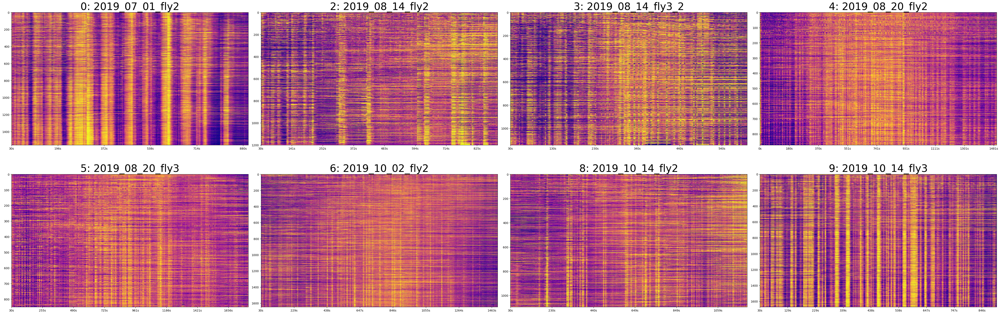

In [35]:
ids = [0, 2, 3, 4, 5, 6, 8, 9]

fig, axis = plt.subplots(2, int(len(ids) / 2), figsize=(12 * int(len(ids) / 2), 8 * 2), squeeze=False)

for i in ids:
	ax = axis[ids.index(i) // int(len(ids) / 2), ids.index(i) % int(len(ids) / 2)]

	name, trace = list(traces.items())[i]

	data = trace['nwb']['data']
	timestamps = trace['nwb']['timestamps']

	ax.imshow(np.clip(data, -0.015, 0.015).T, cmap='plasma', aspect='auto')
	ax.set_box_aspect(9/16)

	xticks = ax.get_xticks()
	ax.set_xticks(xticks[1:-1])
	ax.set_xticklabels(np.array([f'{timestamps[int(round(n))]:.0f}s' for n in xticks[1:-1]]))

	ax.set_title(f'{str(i)}: {name}', fontsize=35)

plt.tight_layout()
plt.savefig('../out/plots/heatmaps.png')

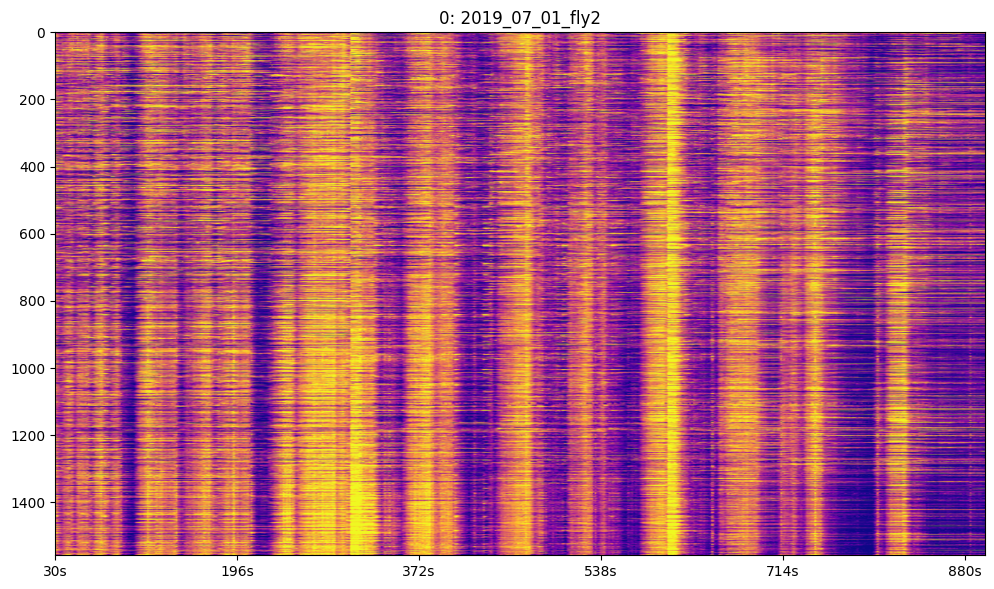

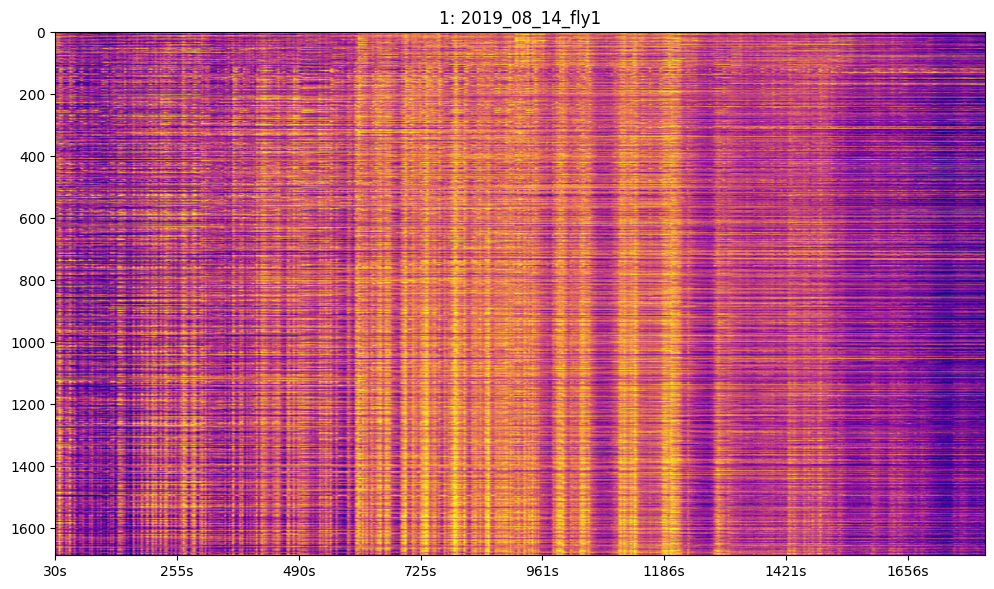

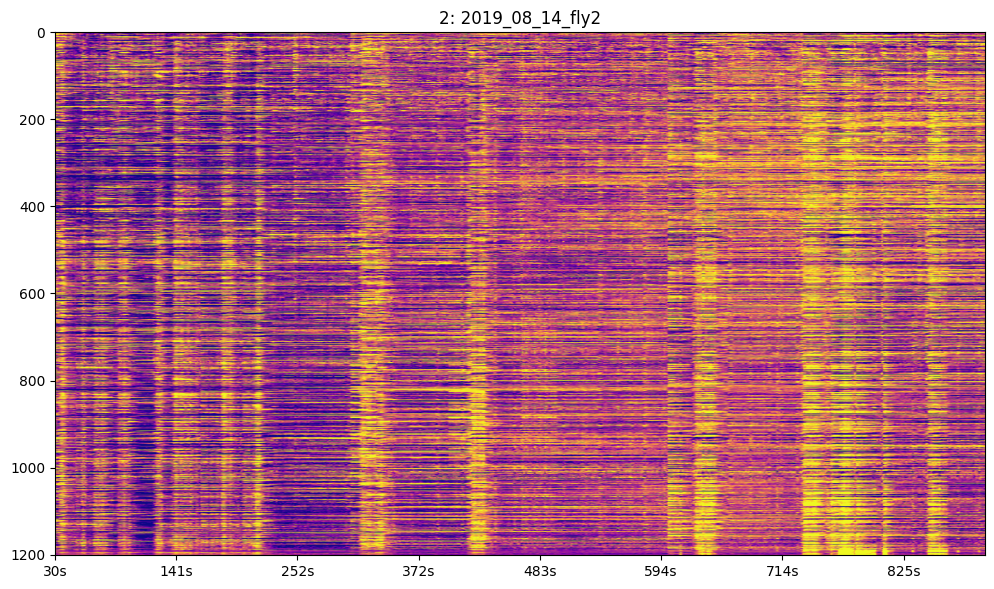

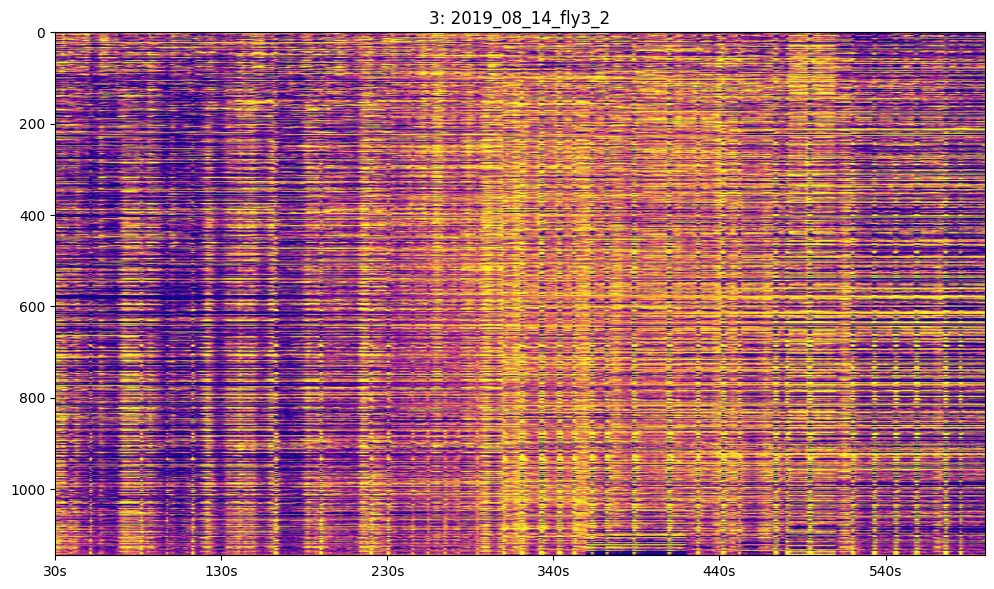

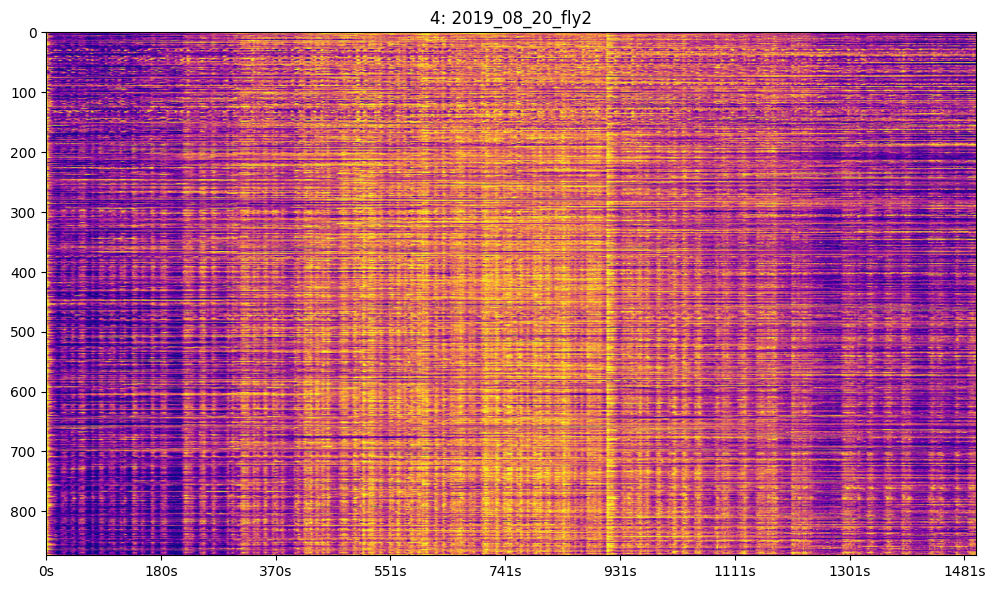

...

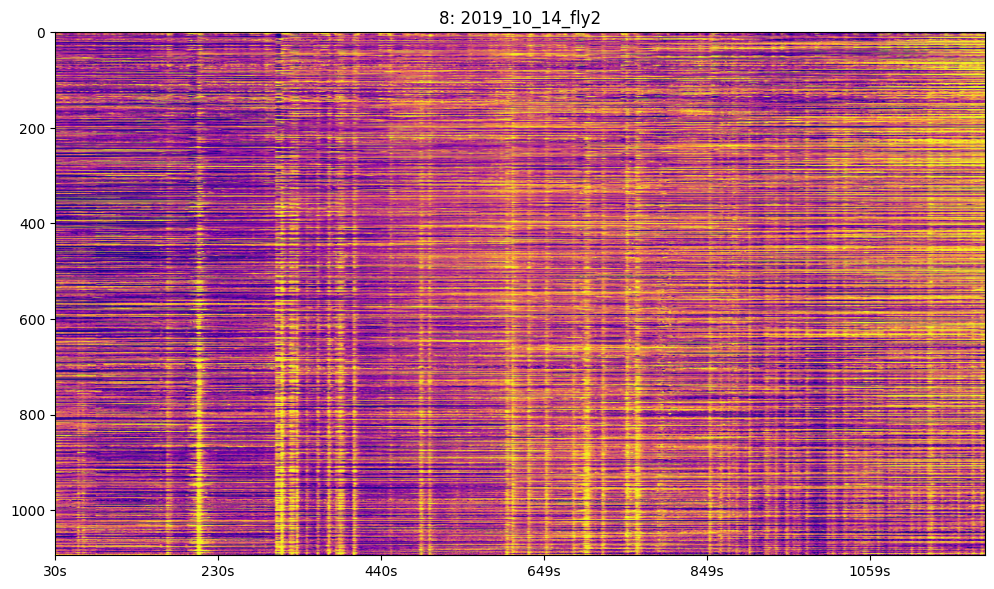

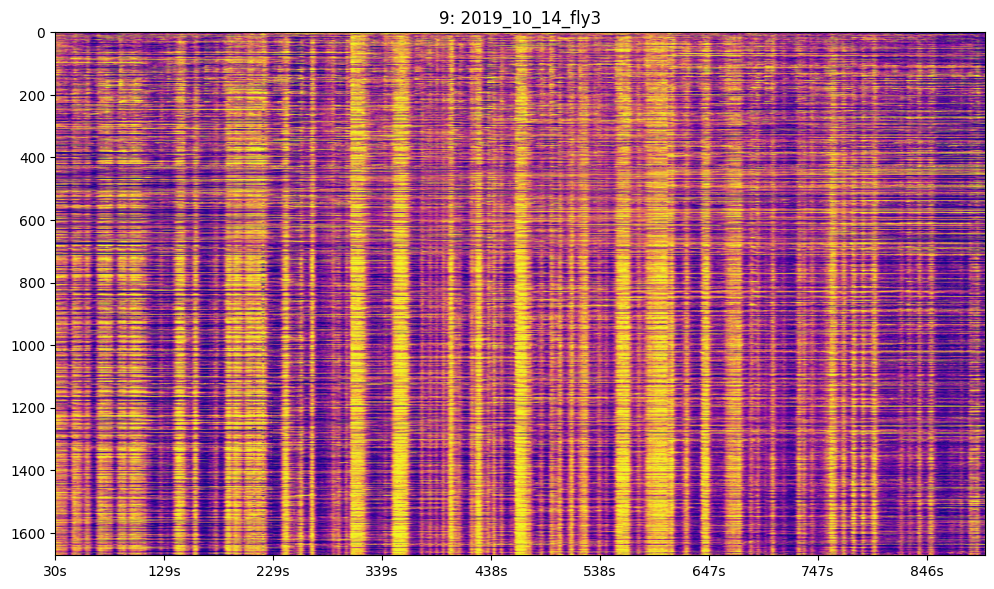

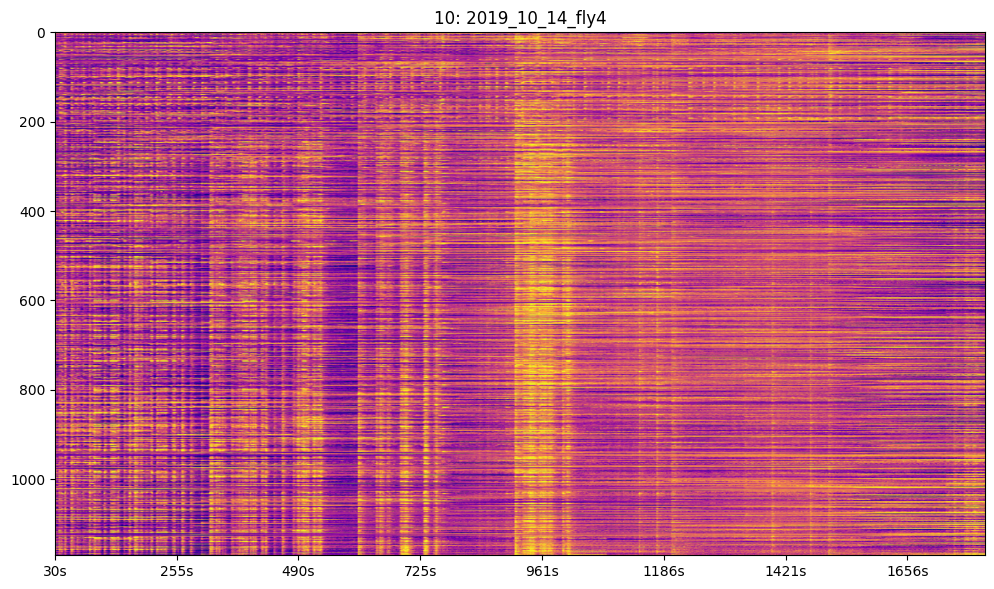

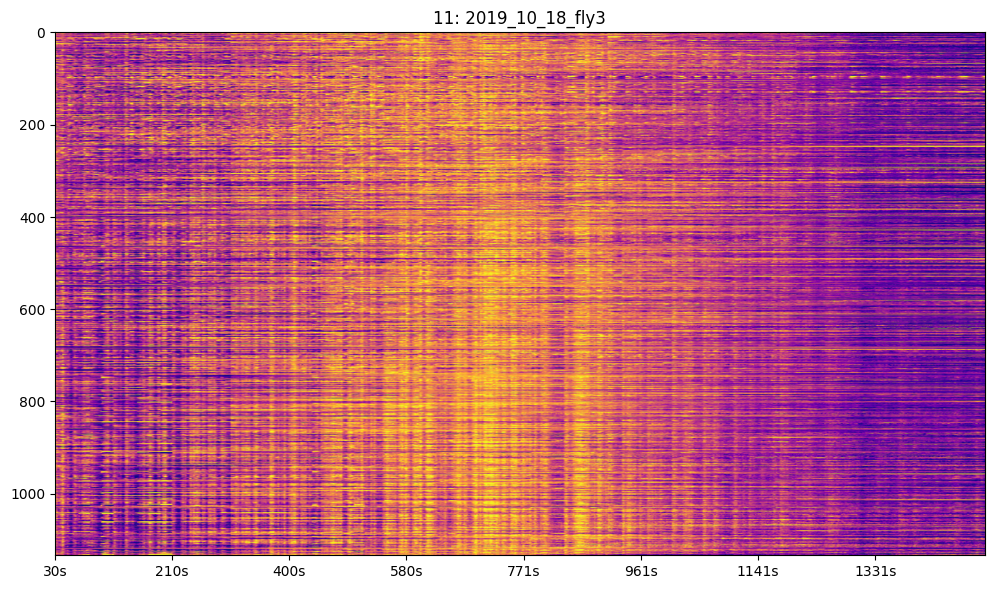

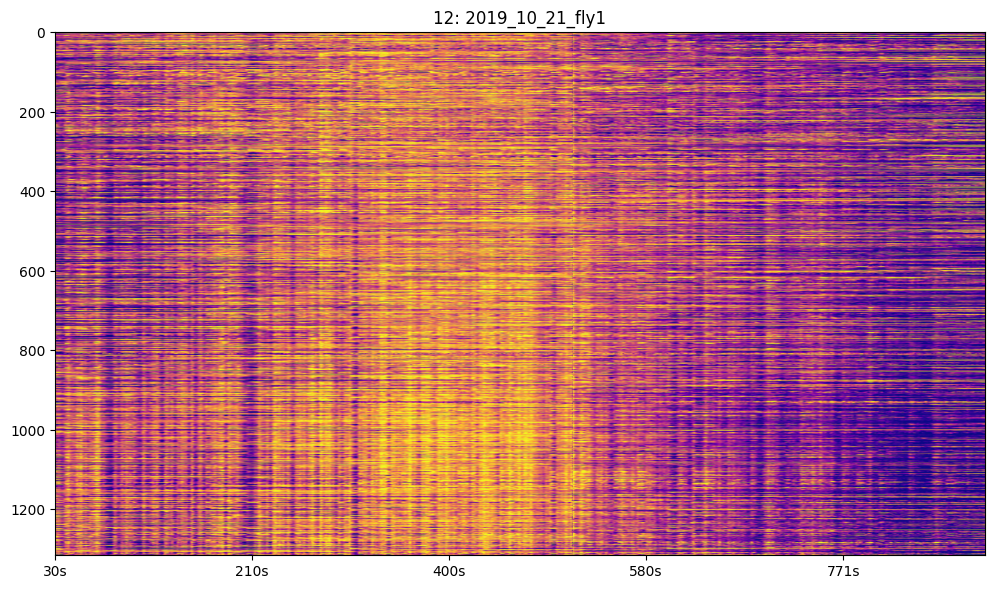

In [8]:
for i, (name, trace) in enumerate(traces.items()):
	fig, axis = plt.subplots(1, 1, figsize=(12, 8), squeeze=False)
	ax = axis[0, 0]

	data = trace['nwb']['data']
	timestamps = trace['nwb']['timestamps']

	ax.imshow(np.clip(data, -0.015, 0.015).T, cmap='plasma', aspect='auto')
	ax.set_box_aspect(9/16)

	xticks = ax.get_xticks()
	ax.set_xticks(xticks[1:-1])
	ax.set_xticklabels(np.array([f'{timestamps[int(round(n))]:.0f}s' for n in xticks[1:-1]]))

	ax.set_title(f'{str(i)}: {name}')

	plt.savefig(f'../out/plots/heatmaps/{str(i)}_{name}.png', bbox_inches='tight')

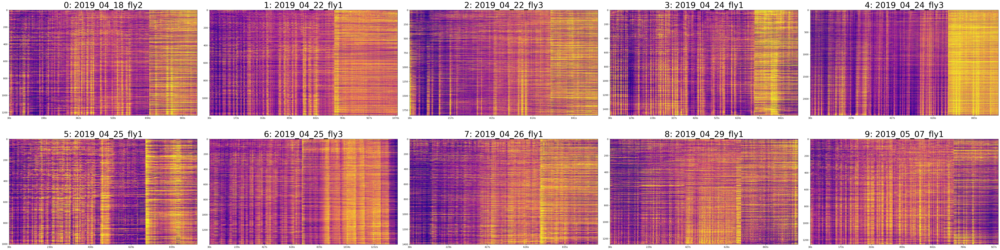

In [9]:
ids = range(len(traces_runflail))

fig, axis = plt.subplots(2, int(len(ids) / 2), figsize=(12 * int(len(ids) / 2), 8 * 2), squeeze=False)

for i in ids:
	ax = axis[ids.index(i) // int(len(ids) / 2), ids.index(i) % int(len(ids) / 2)]

	name, trace = list(traces_runflail.items())[i]

	data = trace['nwb']['data']
	timestamps = trace['nwb']['timestamps']

	ax.imshow(np.clip(data, -0.015, 0.015).T, cmap='plasma', aspect='auto')
	ax.set_box_aspect(9/16)

	xticks = ax.get_xticks()
	ax.set_xticks(xticks[1:-1])
	ax.set_xticklabels(np.array([f'{timestamps[int(round(n))]:.0f}s' for n in xticks[1:-1]]))

	ax.set_title(f'{str(i)}: {name}', fontsize=35)

plt.tight_layout()
plt.savefig('../out/plots/heatmaps_rf.png')

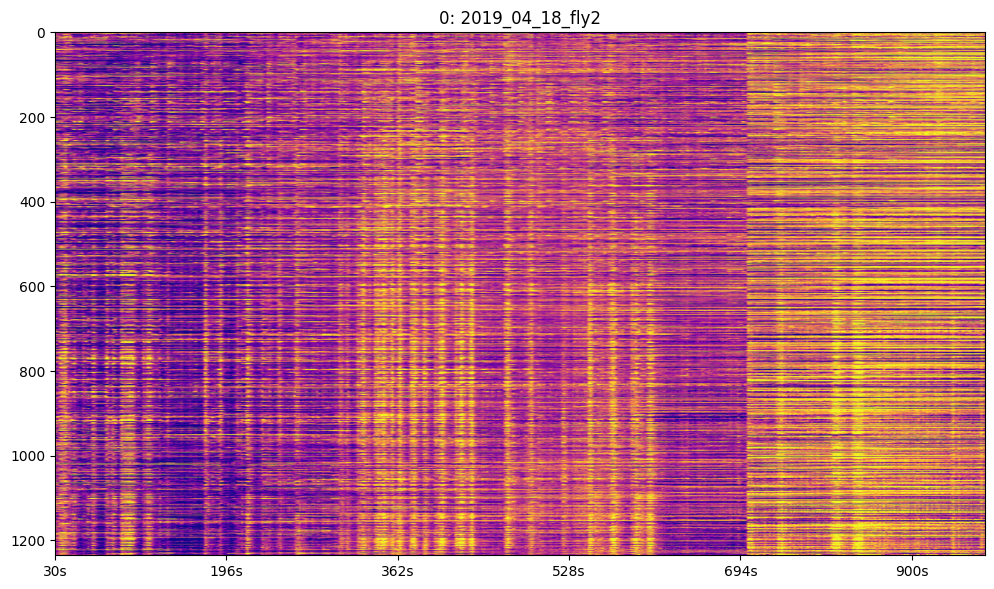

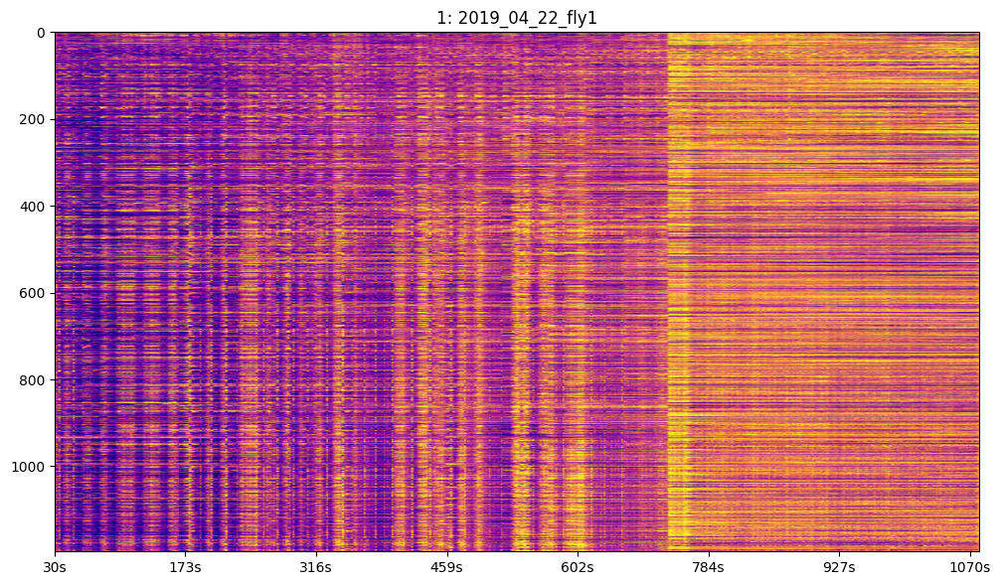

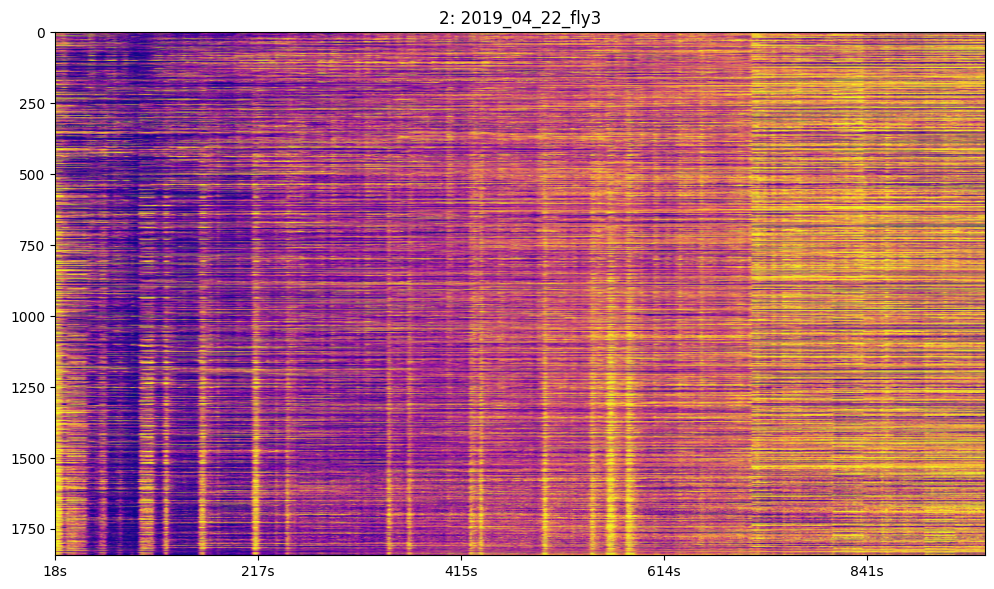

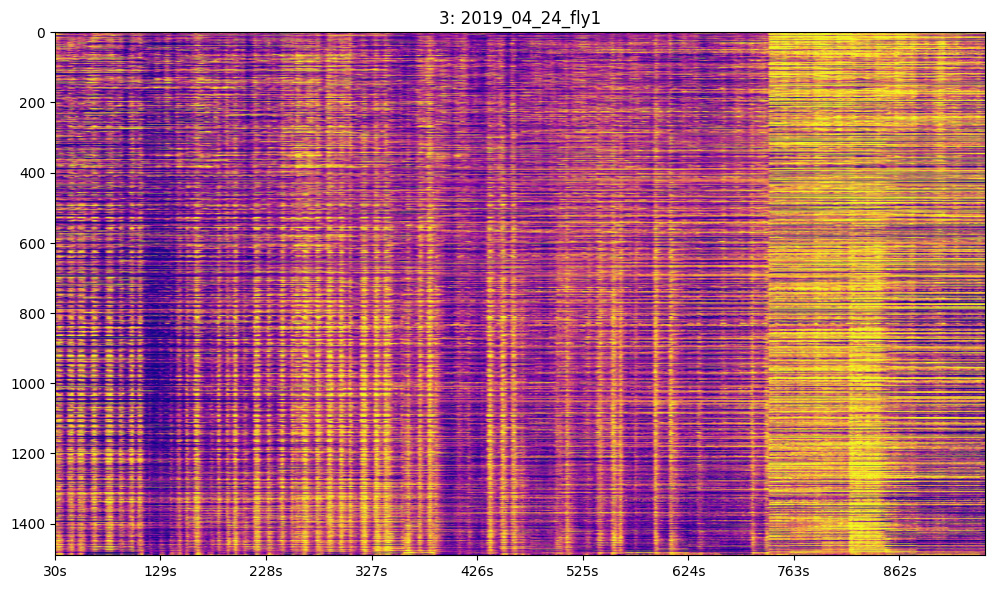

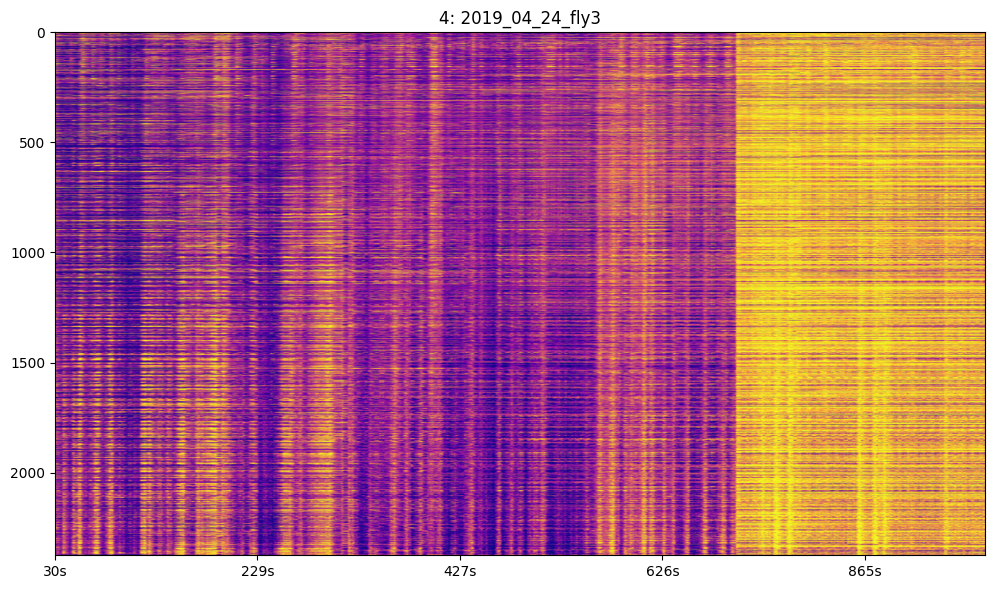

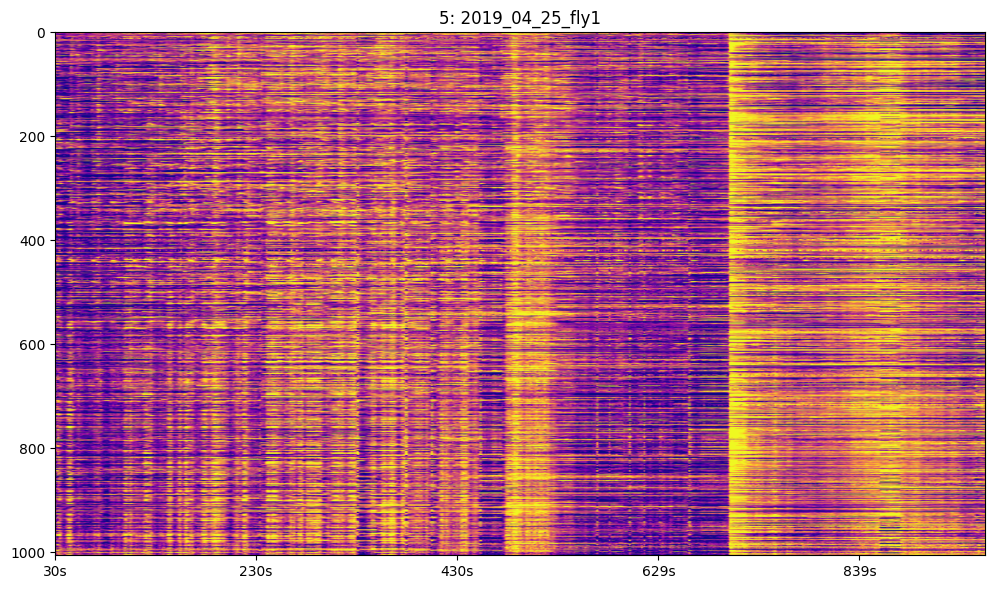

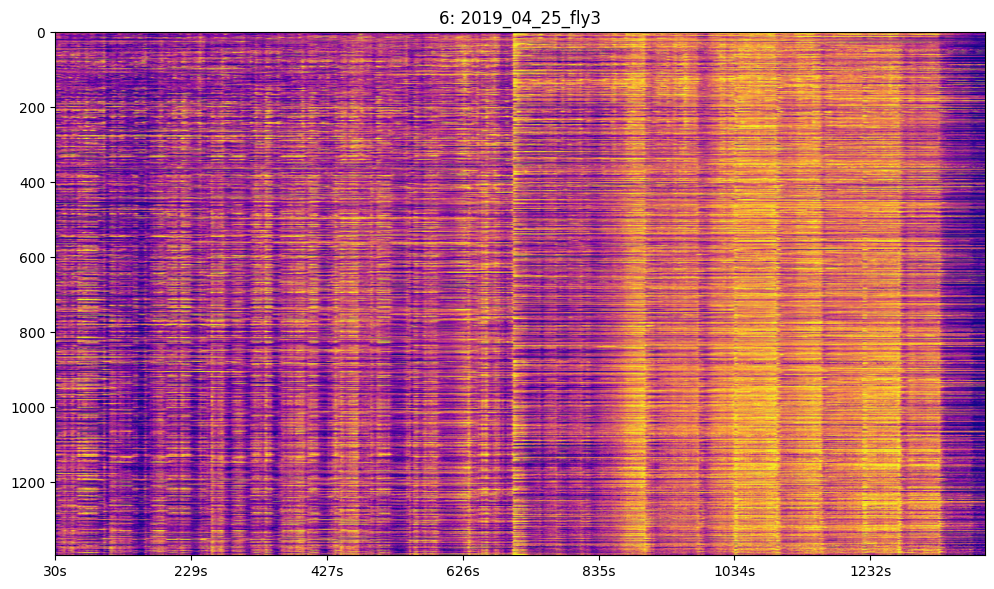

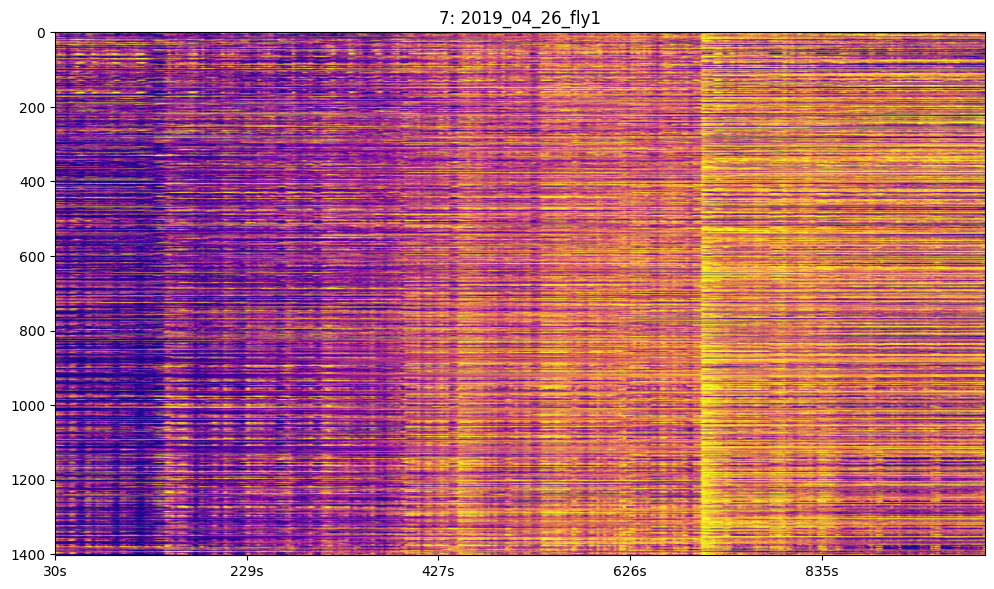

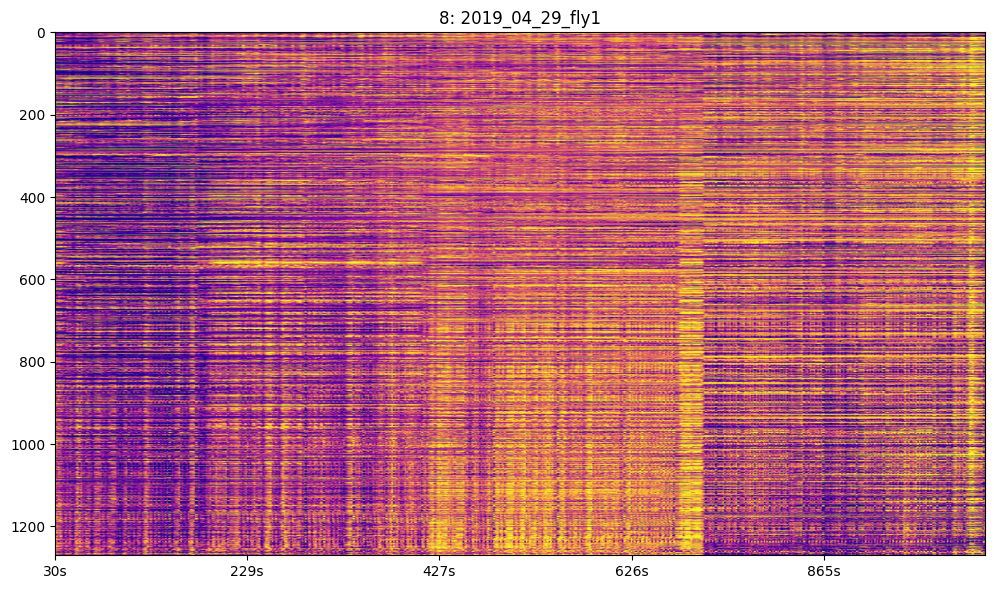

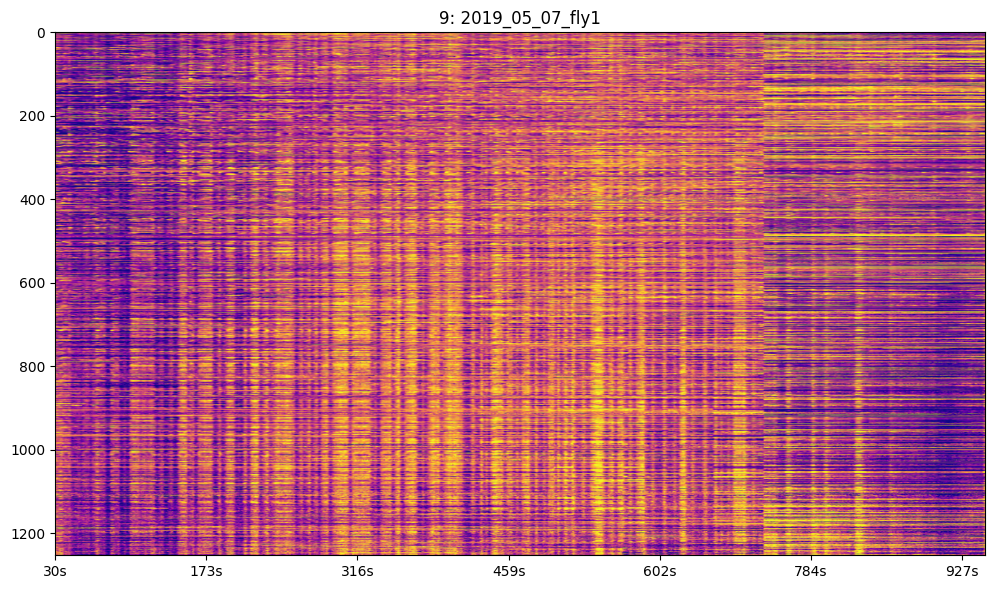

In [10]:
for i, (name, trace) in enumerate(traces_runflail.items()):
	data = trace['nwb']['data']
	timestamps = trace['nwb']['timestamps']

	fig, axis = plt.subplots(1, 1, figsize=(12, 8), squeeze=False)
	ax = axis[0, 0]
	ax.imshow(np.clip(data, -0.015, 0.015).T, cmap='plasma', aspect='auto')
	ax.set_box_aspect(9/16)

	xticks = ax.get_xticks()
	ax.set_xticks(xticks[1:-1])
	ax.set_xticklabels(np.array([f'{timestamps[int(round(n))]:.0f}s' for n in xticks[1:-1]]))

	ax.set_title(f'{str(i)}: {name}')

	plt.savefig(f'../out/plots/heatmaps/flailing/{str(i)}_{name}.png', bbox_inches='tight')

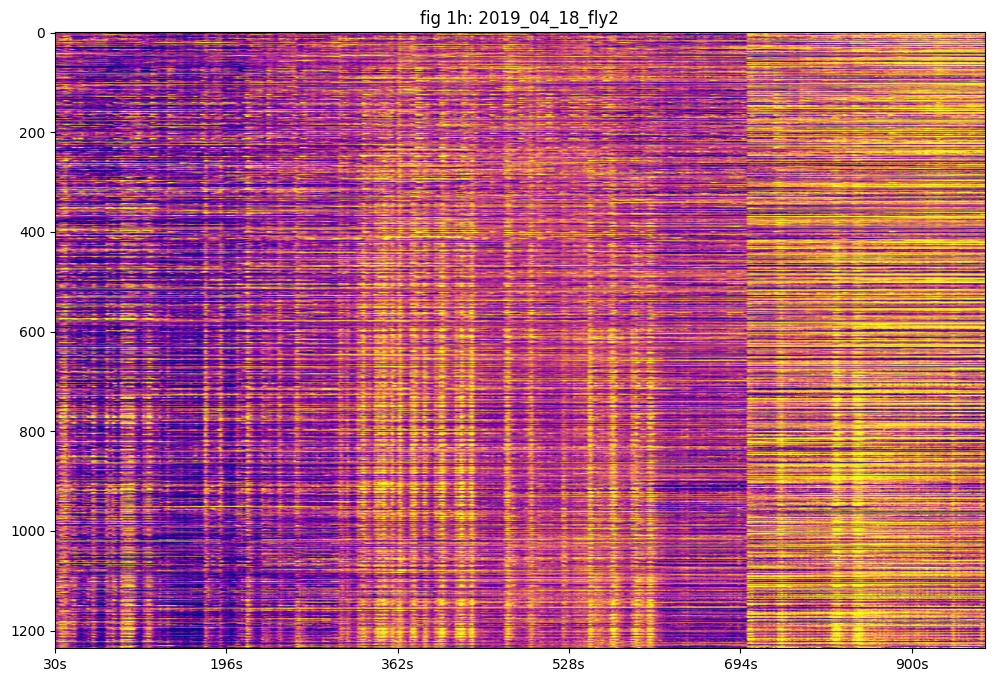

In [11]:
fig, ax = plt.subplots(figsize=(12, 8))
data = traces_runflail['2019_04_18_fly2']['nwb']['data']
timestamps = traces_runflail['2019_04_18_fly2']['nwb']['timestamps']
ax.imshow(np.clip(data, -0.015, 0.015).T, aspect='auto', cmap='plasma')
xticks = plt.xticks()[0]
plt.xticks(xticks[1:-1], labels=np.array([f'{timestamps[int(round(n))]:.0f}s' for n in xticks[1:-1]]))
plt.title(f'fig 1h: 2019_04_18_fly2')
plt.show()

In [12]:
# for i, (name, trace) in enumerate(traces.items()):
# 	data = trace['pickle']['dFF'].T
# 	timestamps = trace['nwb']['timestamps']
#
# 	fig, axis = plt.subplots(1, 1, figsize=(12, 8), squeeze=False)
# 	ax = axis[0, 0]
# 	ax.imshow(np.clip(data, -0.015, 0.015).T, cmap='plasma', aspect='auto')
# 	ax.set_box_aspect(9/16)
#
# 	xticks = ax.get_xticks()
# 	ax.set_xticks(xticks[1:-1])
# 	ax.set_xticklabels(np.array([f'{timestamps[int(round(n))]:.0f}s' for n in xticks[1:-1]]))
#
# 	ax.set_title(name)